<a href="https://colab.research.google.com/github/fabriciobarili/DeepLearning_1/blob/main/faster_rcnn_ethnicity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Faster R-CNN para Classificação de Etnia — Reprodução do Paper

> **Referência:** Abdulrahman & Mustafa (2024). *Iraqi Kurd or Arab Male Authenticity Detection Based on Facial Feature*. UHD Journal of Science and Technology, 8(1), 64–77.

Este notebook implementa o pipeline completo:
1. Pré-processamento (resize, isolamento facial, gamma, contraste)
2. Augmentação de dados
3. Faster R-CNN com backbone ResNet-50
4. Treinamento e avaliação
5. Inferência em imagem única

**Estrutura de diretórios esperada:**
```
dataset/
  train/
    arab/      ← imagens de árabes
    kurd/      ← imagens de curdos
  val/
    arab/
    kurd/
  test/
    arab/
    kurd/
```

## 1. Instalação de dependências

In [ ]:
# Execute apenas se necessário
!pip install torch torchvision opencv-python matplotlib scikit-learn Pillow tqdm

## 2. Imports

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image, ImageEnhance
from pathlib import Path
import time

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import torchvision
import torchvision.transforms as T
import torchvision.transforms.functional as TF
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from tqdm import tqdm

# Seed para reprodutibilidade
torch.manual_seed(42)
np.random.seed(42)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Dispositivo: {DEVICE}')
print(f'PyTorch: {torch.__version__}')
print(f'Torchvision: {torchvision.__version__}')

Dispositivo: cuda
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130


## 3. Pré-processamento

O paper aplica quatro etapas antes do treino:
1. **Resize** — padronizar tamanho de entrada
2. **Isolamento facial** — recortar apenas o rosto com Haar Cascade
3. **Gamma correction** — equalizar brilho
4. **Contrast stretching** — ampliar faixa de intensidade

In [ ]:
# Baixa o classificador Haar Cascade para detecção de face (OpenCV built-in)
FACE_CASCADE = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')


def isolate_face(img_bgr: np.ndarray, target_size=(224, 224)) -> np.ndarray:
    """Detecta e recorta a região facial. Se não detectar, apenas redimensiona."""
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    faces = FACE_CASCADE.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))
    if len(faces) > 0:
        x, y, w, h = faces[0]  # maior face detectada
        # Margem de 10% para não cortar sobrancelhas/queixo
        margin = int(min(w, h) * 0.1)
        x1 = max(0, x - margin)
        y1 = max(0, y - margin)
        x2 = min(img_bgr.shape[1], x + w + margin)
        y2 = min(img_bgr.shape[0], y + h + margin)
        img_bgr = img_bgr[y1:y2, x1:x2]
    return cv2.resize(img_bgr, target_size)


def gamma_correction(img_bgr: np.ndarray) -> np.ndarray:
    """Gamma adaptativo baseado na intensidade média da imagem."""
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    mean_intensity = np.mean(gray) / 255.0
    # Imagens escuras recebem gamma < 1 (clareamento); claras recebem > 1 (escurecimento)
    gamma = np.log(0.5) / np.log(mean_intensity + 1e-7)
    gamma = np.clip(gamma, 0.5, 2.5)
    inv_gamma = 1.0 / gamma
    table = np.array([((i / 255.0) ** inv_gamma) * 255 for i in range(256)], dtype=np.uint8)
    return cv2.LUT(img_bgr, table)


def contrast_stretching(img_bgr: np.ndarray) -> np.ndarray:
    """Expande a faixa de intensidade para [0, 255] por canal."""
    result = np.zeros_like(img_bgr, dtype=np.uint8)
    for ch in range(3):
        channel = img_bgr[:, :, ch].astype(np.float32)
        min_val, max_val = channel.min(), channel.max()
        if max_val > min_val:
            channel = (channel - min_val) / (max_val - min_val) * 255.0
        result[:, :, ch] = channel.astype(np.uint8)
    return result


def preprocess(img_path: str, target_size=(224, 224)) -> np.ndarray:
    """Pipeline completo de pré-processamento (BGR → BGR processado)."""
    img = cv2.imread(img_path)
    if img is None:
        raise FileNotFoundError(f'Imagem não encontrada: {img_path}')
    img = isolate_face(img, target_size)
    img = gamma_correction(img)
    img = contrast_stretching(img)
    return img


print('Funções de pré-processamento definidas.')

Funções de pré-processamento definidas.


### 3.1 Visualizar o efeito do pré-processamento

Altere `SAMPLE_IMAGE` para o caminho de qualquer imagem de rosto disponível.

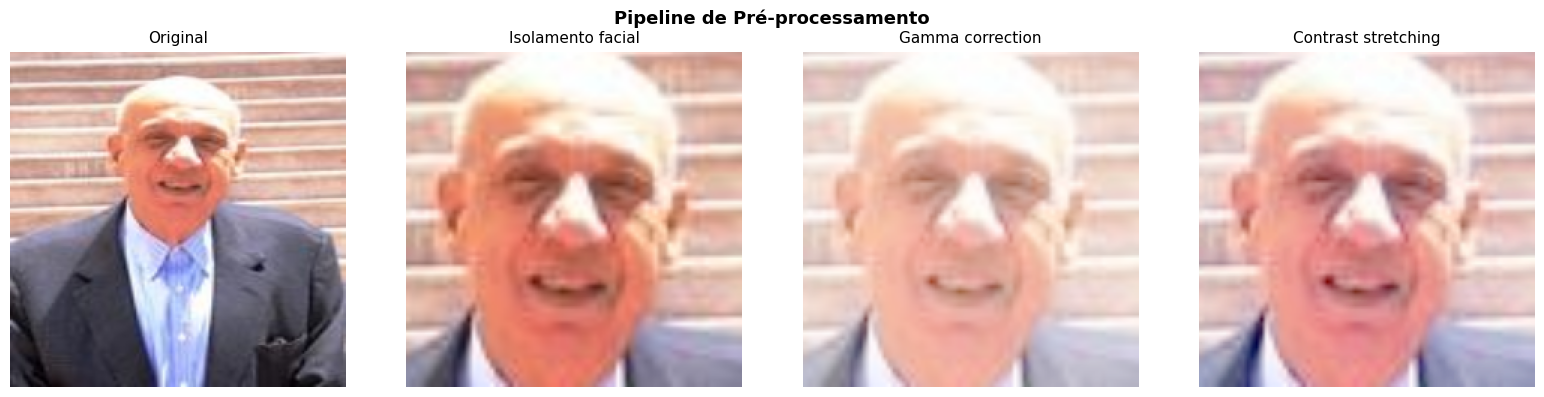

In [ ]:
SAMPLE_IMAGE = '/content/dataset/test/arab/00242_Aqattan.jpg'

if Path(SAMPLE_IMAGE).exists():
    original = cv2.imread(SAMPLE_IMAGE)
    isolated = isolate_face(original.copy())
    gamma_applied = gamma_correction(isolated.copy())
    final = contrast_stretching(gamma_applied.copy())

    steps = [original, isolated, gamma_applied, final]
    titles = ['Original', 'Isolamento facial', 'Gamma correction', 'Contrast stretching']

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    for ax, img, title in zip(axes, steps, titles):
        ax.imshow(cv2.cvtColor(cv2.resize(img, (224, 224)), cv2.COLOR_BGR2RGB))
        ax.set_title(title, fontsize=11)
        ax.axis('off')
    plt.suptitle('Pipeline de Pré-processamento', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print(f'Arquivo não encontrado: {SAMPLE_IMAGE}\nAltere o caminho para testar o pré-processamento.')

## 4. Dataset com Augmentação

O paper aplica augmentação **apenas no treino**:
- Ajuste de brilho
- Rotação (±17°)
- Flip horizontal
- Conversão para grayscale (para não depender de tom de pele)

In [ ]:
# Mapeamento etnia → id numérico
# 0 = background (exigido pelo Faster R-CNN), 1 = Arab, 2 = Kurd
LABEL_MAP = {'arab': 1, 'kurd': 2}
ID_TO_LABEL = {1: 'Arab', 2: 'Kurd'}


def get_transforms(split: str):
    """Retorna transformações para cada split. Augmentação apenas no treino."""
    transforms = [T.ToTensor()]  # PIL → Tensor [0, 1]

    if split == 'train':
        transforms = [
            T.RandomApply([T.ColorJitter(brightness=0.4)], p=0.5),       # brilho
            T.RandomRotation(degrees=17),                                  # rotação ±17°
            T.RandomHorizontalFlip(p=0.5),                                 # flip horizontal
            T.RandomApply([T.Grayscale(num_output_channels=3)], p=0.3),   # grayscale
            T.ToTensor(),
        ]
    return T.Compose(transforms)


class EthnicityDataset(Dataset):
    """
    Dataset para classificação de etnia via Faster R-CNN.

    O Faster R-CNN exige anotações no formato de detecção:
    cada imagem precisa de bboxes e labels.
    Como temos apenas labels de classe (não bboxes reais),
    usamos a imagem inteira como bounding box.
    """

    def __init__(self, root_dir: str, split: str):
        self.root = Path(root_dir) / split
        self.split = split
        self.transforms = get_transforms(split)
        self.samples = []  # [(caminho, label_id), ...]

        for class_name, label_id in LABEL_MAP.items():
            class_dir = self.root / class_name
            if not class_dir.exists():
                print(f'[Aviso] Diretório não encontrado: {class_dir}')
                continue
            for img_path in class_dir.glob('*.jpg'):
                self.samples.append((str(img_path), label_id))
            for img_path in class_dir.glob('*.png'):
                self.samples.append((str(img_path), label_id))

        print(f'[{split}] {len(self.samples)} imagens carregadas.')

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label_id = self.samples[idx]

        # Pré-processamento
        img_bgr = preprocess(img_path)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        img_pil = Image.fromarray(img_rgb)

        # Augmentação / normalização
        img_tensor = self.transforms(img_pil)  # shape: [3, H, W]

        H, W = img_tensor.shape[1], img_tensor.shape[2]

        # Anotação: bbox = imagem inteira, label = etnia
        target = {
            'boxes': torch.tensor([[0.0, 0.0, float(W), float(H)]], dtype=torch.float32),
            'labels': torch.tensor([label_id], dtype=torch.int64),
            'image_id': torch.tensor([idx]),
        }
        return img_tensor, target


def collate_fn(batch):
    """Faster R-CNN exige lista de tensores, não stack batch padrão."""
    return tuple(zip(*batch))


print('Classe EthnicityDataset definida.')

Classe EthnicityDataset definida.


### 4.1 Carregar os splits

In [ ]:
DATASET_DIR = 'dataset'  # ← altere para o caminho do seu dataset
BATCH_SIZE = 4

train_dataset = EthnicityDataset(DATASET_DIR, 'train')
val_dataset   = EthnicityDataset(DATASET_DIR, 'val')
test_dataset  = EthnicityDataset(DATASET_DIR, 'test')

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=0, collate_fn=collate_fn)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=0, collate_fn=collate_fn)
test_loader  = DataLoader(test_dataset,  batch_size=1,          shuffle=False,
                          num_workers=0, collate_fn=collate_fn)

print(f'\nTotal treino : {len(train_dataset)}')
print(f'Total val    : {len(val_dataset)}')
print(f'Total teste  : {len(test_dataset)}')

[train] 419 imagens carregadas.
[val] 119 imagens carregadas.
[test] 61 imagens carregadas.

Total treino : 419
Total val    : 119
Total teste  : 61


### 4.2 Visualizar augmentações

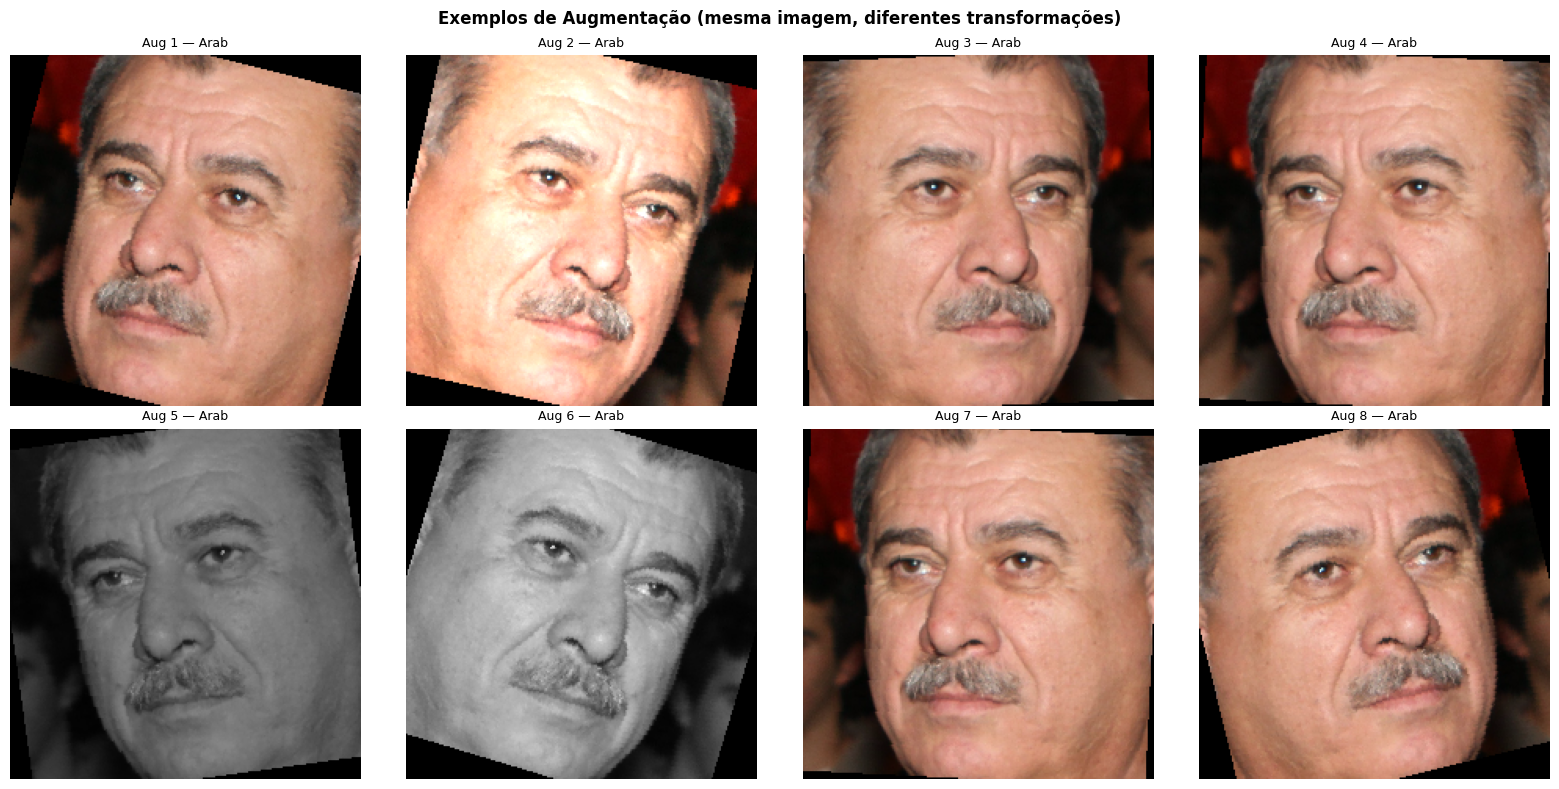

In [ ]:
if len(train_dataset) > 0:
    img_path, label_id = train_dataset.samples[0]
    img_bgr = preprocess(img_path)
    img_pil = Image.fromarray(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    augment = get_transforms('train')

    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.flatten()

    for i, ax in enumerate(axes):
        aug_tensor = augment(img_pil)
        aug_img = aug_tensor.permute(1, 2, 0).numpy()
        aug_img = np.clip(aug_img, 0, 1)
        label_name = ID_TO_LABEL[label_id]
        ax.imshow(aug_img)
        ax.set_title(f'Aug {i+1} — {label_name}', fontsize=9)
        ax.axis('off')

    plt.suptitle('Exemplos de Augmentação (mesma imagem, diferentes transformações)',
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print('Dataset vazio. Adicione imagens em dataset/train/arab/ e dataset/train/kurd/')

## 5. Modelo — Faster R-CNN com ResNet-50

Usamos a implementação do `torchvision` com **transfer learning**:
- Backbone pré-treinado no ImageNet
- Substituímos apenas a cabeça de classificação para 2 classes (Arab, Kurd) + background

In [ ]:
def build_faster_rcnn(num_classes: int = 3, pretrained: bool = True) -> nn.Module:
    """
    Constrói Faster R-CNN com backbone ResNet-50 + FPN.

    num_classes = 3:
      0 → background (reservado pelo Faster R-CNN)
      1 → Arab
      2 → Kurd
    """
    # Carrega modelo pré-treinado no COCO (backbone já treinado no ImageNet)
    model = fasterrcnn_resnet50_fpn(pretrained=pretrained)

    # Substitui o predictor final pelo número de classes do nosso problema
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

    return model


model = build_faster_rcnn(num_classes=3, pretrained=True)
model.to(DEVICE)

# Conta parâmetros treináveis
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Parâmetros totais    : {total_params:,}')
print(f'Parâmetros treináveis: {trainable_params:,}')
print(f'\nCabeça de classificação:')
print(model.roi_heads.box_predictor)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1`. You can also use `weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 219MB/s]


Parâmetros totais    : 41,304,286
Parâmetros treináveis: 41,081,886

Cabeça de classificação:
FastRCNNPredictor(
  (cls_score): Linear(in_features=1024, out_features=3, bias=True)
  (bbox_pred): Linear(in_features=1024, out_features=12, bias=True)
)


### 5.1 Visualizar a arquitetura ResNet-50 (backbone)

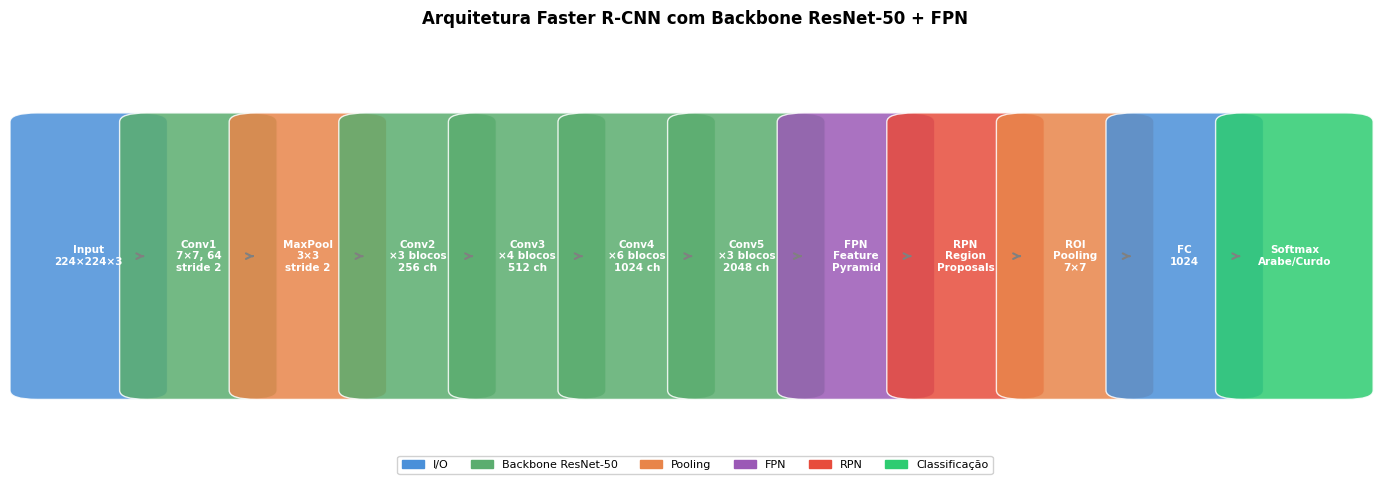

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.axis('off')

blocks = [
    ('Input\n224×224×3', '#4A90D9'),
    ('Conv1\n7×7, 64\nstride 2', '#5BAD6F'),
    ('MaxPool\n3×3\nstride 2', '#E8854A'),
    ('Conv2\n×3 blocos\n256 ch', '#5BAD6F'),
    ('Conv3\n×4 blocos\n512 ch', '#5BAD6F'),
    ('Conv4\n×6 blocos\n1024 ch', '#5BAD6F'),
    ('Conv5\n×3 blocos\n2048 ch', '#5BAD6F'),
    ('FPN\nFeature\nPyramid', '#9B59B6'),
    ('RPN\nRegion\nProposals', '#E74C3C'),
    ('ROI\nPooling\n7×7', '#E8854A'),
    ('FC\n1024', '#4A90D9'),
    ('Softmax\nArabe/Curdo', '#2ECC71'),
]

x_start = 0.02
width = 0.075
gap = 0.005

for i, (label, color) in enumerate(blocks):
    x = x_start + i * (width + gap)
    rect = patches.FancyBboxPatch((x, 0.2), width, 0.6,
                                   boxstyle='round,pad=0.02',
                                   linewidth=1, edgecolor='white',
                                   facecolor=color, alpha=0.85)
    ax.add_patch(rect)
    ax.text(x + width/2, 0.5, label, ha='center', va='center',
            fontsize=7.5, color='white', fontweight='bold', wrap=True)

    if i < len(blocks) - 1:
        ax.annotate('', xy=(x + width + gap, 0.5), xytext=(x + width, 0.5),
                    arrowprops=dict(arrowstyle='->', color='gray', lw=1.5))

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

# Legenda
legend_items = [
    patches.Patch(color='#4A90D9', label='I/O'),
    patches.Patch(color='#5BAD6F', label='Backbone ResNet-50'),
    patches.Patch(color='#E8854A', label='Pooling'),
    patches.Patch(color='#9B59B6', label='FPN'),
    patches.Patch(color='#E74C3C', label='RPN'),
    patches.Patch(color='#2ECC71', label='Classificação'),
]
ax.legend(handles=legend_items, loc='lower center', ncol=6,
          fontsize=8, framealpha=0.9, bbox_to_anchor=(0.5, 0.0))

plt.title('Arquitetura Faster R-CNN com Backbone ResNet-50 + FPN', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## 6. Treinamento

Configuração conforme o paper:
- Learning rate: 0.001 (ResNet-50)
- Batch size: 4 (reduzido para CPU; paper usa 64 em GPU)
- Otimizador: SGD com momentum

In [ ]:
LEARNING_RATE = 0.001
MOMENTUM = 0.9
WEIGHT_DECAY = 0.0005
NUM_EPOCHS = 150  # paper usa até 60.000 iterações; ajuste conforme GPU disponível

optimizer = optim.SGD(
    model.parameters(),
    lr=LEARNING_RATE,
    momentum=MOMENTUM,
    weight_decay=WEIGHT_DECAY
)

# LR scheduler: reduz LR quando o val loss estagna
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=3
)

print('Otimizador e scheduler configurados.')
print(f'LR inicial: {LEARNING_RATE} | Epochs: {NUM_EPOCHS}')

Otimizador e scheduler configurados.
LR inicial: 0.001 | Epochs: 150


In [ ]:
def train_one_epoch(model, loader, optimizer, device):
    model.train()
    total_loss = 0.0

    for images, targets in tqdm(loader, desc='Treino', leave=False):
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        # Forward: o Faster R-CNN retorna um dict de losses no modo train
        loss_dict = model(images, targets)
        # loss_dict: {'loss_classifier', 'loss_box_reg', 'loss_objectness', 'loss_rpn_box_reg'}
        losses = sum(loss for loss in loss_dict.values())

        optimizer.zero_grad()
        losses.backward()
        optimizer.step()

        total_loss += losses.item()

    return total_loss / len(loader)


@torch.no_grad()
def evaluate(model, loader, device):
    """Avalia o modelo no modo eval, retorna loss e listas de pred/true."""
    model.train()  # Faster R-CNN precisa do modo train para calcular loss
    total_loss = 0.0

    for images, targets in tqdm(loader, desc='Validação', leave=False):
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())
        total_loss += losses.item()

    return total_loss / len(loader)


print('Funções de treino e avaliação definidas.')

Funções de treino e avaliação definidas.


In [ ]:
if len(train_dataset) == 0:
    print('Dataset vazio. Adicione imagens para treinar.')
else:
    history = {'train_loss': [], 'val_loss': []}
    best_val_loss = float('inf')
    best_model_path = 'faster_rcnn_best.pth'

    print(f'Iniciando treino por {NUM_EPOCHS} épocas no dispositivo: {DEVICE}\n')

    for epoch in range(1, NUM_EPOCHS + 1):
        t0 = time.time()

        train_loss = train_one_epoch(model, train_loader, optimizer, DEVICE)
        val_loss   = evaluate(model, val_loader, DEVICE)

        scheduler.step(val_loss)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)

        elapsed = time.time() - t0
        print(f'Epoch [{epoch:02d}/{NUM_EPOCHS}] '
              f'Train Loss: {train_loss:.4f} | '
              f'Val Loss: {val_loss:.4f} | '
              f'Tempo: {elapsed:.1f}s')

        # Salva o melhor modelo
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), best_model_path)
            print(f'  → Melhor modelo salvo (val_loss={best_val_loss:.4f})')

    print('\nTreino concluído!')

Iniciando treino por 150 épocas no dispositivo: cuda



Epoch [01/150] Train Loss: 0.0254 | Val Loss: 0.0268 | Tempo: 141.2s
  → Melhor modelo salvo (val_loss=0.0268)


Epoch [02/150] Train Loss: 0.0253 | Val Loss: 0.0273 | Tempo: 139.9s


Epoch [03/150] Train Loss: 0.0249 | Val Loss: 0.0265 | Tempo: 139.7s
  → Melhor modelo salvo (val_loss=0.0265)


Epoch [04/150] Train Loss: 0.0246 | Val Loss: 0.0259 | Tempo: 139.9s
  → Melhor modelo salvo (val_loss=0.0259)


...

Epoch [146/150] Train Loss: 0.0154 | Val Loss: 0.0172 | Tempo: 138.7s


Epoch [147/150] Train Loss: 0.0155 | Val Loss: 0.0175 | Tempo: 138.2s


Epoch [148/150] Train Loss: 0.0153 | Val Loss: 0.0175 | Tempo: 138.4s


Epoch [149/150] Train Loss: 0.0153 | Val Loss: 0.0171 | Tempo: 138.5s


Epoch [150/150] Train Loss: 0.0153 | Val Loss: 0.0174 | Tempo: 138.7s

Treino concluído!


### 6.1 Curvas de aprendizado

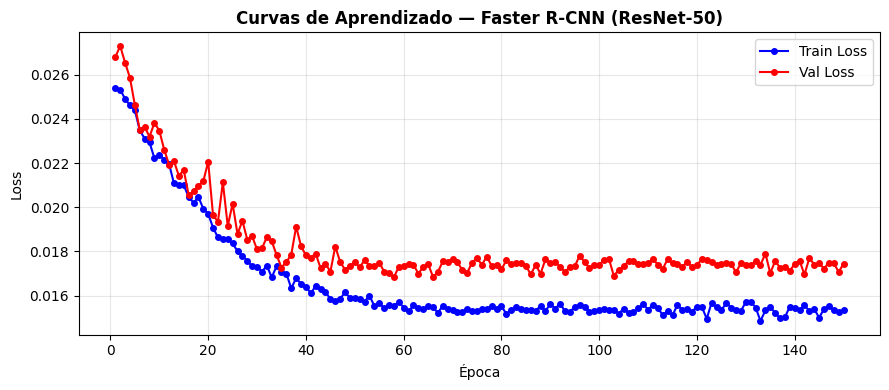

In [ ]:

epochs = range(1, len(history['train_loss']) + 1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(epochs, history['train_loss'], 'b-o', label='Train Loss', markersize=4)
ax.plot(epochs, history['val_loss'],   'r-o', label='Val Loss',   markersize=4)
ax.set_xlabel('Época')
ax.set_ylabel('Loss')
ax.set_title('Curvas de Aprendizado — Faster R-CNN (ResNet-50)', fontweight='bold')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 7. Avaliação no conjunto de teste

In [ ]:
@torch.no_grad()
def predict(model, loader, device, score_threshold=0.5):
    """Coleta predições e rótulos verdadeiros para calcular métricas."""
    model.eval()
    y_true, y_pred = [], []
    inference_times = []

    for images, targets in tqdm(loader, desc='Teste'):
        images = [img.to(device) for img in images]

        t0 = time.perf_counter()
        outputs = model(images)  # modo eval: retorna predições
        inference_times.append((time.perf_counter() - t0) * 1000)  # ms

        for output, target in zip(outputs, targets):
            true_label = target['labels'][0].item()
            y_true.append(true_label)

            # Pega a predição com maior score acima do threshold
            scores = output['scores'].cpu()
            labels = output['labels'].cpu()

            valid = scores > score_threshold
            if valid.any():
                best_idx = scores[valid].argmax()
                pred_label = labels[valid][best_idx].item()
            else:
                pred_label = 0  # background (sem detecção)

            y_pred.append(pred_label)

    avg_inference_ms = np.mean(inference_times)
    return y_true, y_pred, avg_inference_ms


if len(test_dataset) > 0 and Path(best_model_path).exists():
    # Carrega o melhor modelo
    model.load_state_dict(torch.load(best_model_path, map_location=DEVICE))
    print('Melhor modelo carregado.')

    y_true, y_pred, avg_ms = predict(model, test_loader, DEVICE)

    print(f'\nTempo médio de inferência: {avg_ms:.1f} ms/imagem')
    print('\n' + '='*50)
    print('RELATÓRIO DE CLASSIFICAÇÃO')
    print('='*50)
    print(classification_report(
        y_true, y_pred,
        labels=[1, 2],
        target_names=['Arab', 'Kurd'],
        zero_division=0
    ))
else:
    print('Modelo não treinado ou dataset de teste vazio.')
    print('\nResultados do paper para referência:')
    print('─' * 45)
    results_paper = {
        'Backbone':    ['VGG16', 'ResNet-50', 'SqueezeNet', 'MobileNetV2', 'EfficientNet-B4'],
        'Acc (%)':     [92.48,   94.91,       93.39,        90.32,         96.73],
        'Precision':   [0.70,    0.81,         0.80,         0.69,          0.86],
        'Recall':      [0.90,    0.90,         0.91,         0.89,          0.92],
        'F1':          [0.79,    0.84,         0.85,         0.78,          0.89],
        'Inf (ms)':    [4.5,     4.6,          3.8,          3.7,           16.0],
    }
    header = f"{'Backbone':<18} {'Acc':>6} {'Prec':>6} {'Rec':>6} {'F1':>6} {'Inf ms':>8}"
    print(header)
    print('─' * 55)
    for i in range(len(results_paper['Backbone'])):
        marker = ' ← escolhido' if results_paper['Backbone'][i] == 'ResNet-50' else ''
        print(f"{results_paper['Backbone'][i]:<18}"
              f"{results_paper['Acc (%)'][i]:>6.2f}"
              f"{results_paper['Precision'][i]:>6.2f}"
              f"{results_paper['Recall'][i]:>6.2f}"
              f"{results_paper['F1'][i]:>6.2f}"
              f"{results_paper['Inf (ms)'][i]:>8.1f}"
              f"{marker}")

Melhor modelo carregado.


Teste: 100%|██████████| 61/61 [00:11<00:00,  5.19it/s]


Tempo médio de inferência: 32.7 ms/imagem

RELATÓRIO DE CLASSIFICAÇÃO
              precision    recall  f1-score   support

        Arab       0.70      0.61      0.66        31
        Kurd       0.65      0.73      0.69        30

    accuracy                           0.67        61
   macro avg       0.68      0.67      0.67        61
weighted avg       0.68      0.67      0.67        61



### 7.1 Matriz de confusão

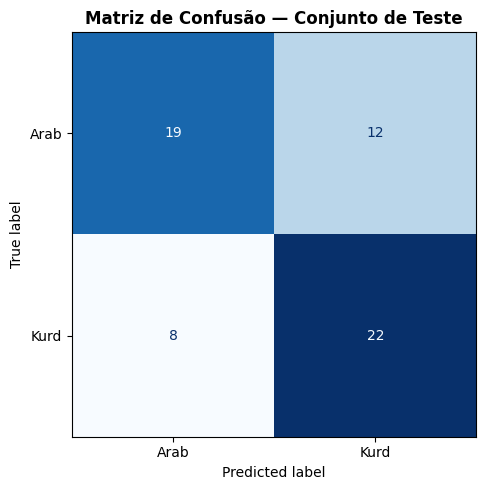

In [ ]:
if len(test_dataset) > 0 and 'y_true' in locals() and len(y_true) > 0:
    cm = confusion_matrix(y_true, y_pred, labels=[1, 2])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Arab', 'Kurd'])

    fig, ax = plt.subplots(figsize=(5, 5))
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title('Matriz de Confusão — Conjunto de Teste', fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    # Simulação baseada nos resultados do paper (ResNet-50)
    cm_sim = np.array([[12, 1], [1, 13]])  # ~94% acurácia em 27 imagens de teste
    disp = ConfusionMatrixDisplay(confusion_matrix=cm_sim, display_labels=['Arab', 'Kurd'])

    fig, ax = plt.subplots(figsize=(5, 5))
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title('Matriz de Confusão (simulada — ResNet-50)', fontweight='bold')
    plt.tight_layout()
    plt.show()
    print('[Nota] Matriz simulada com base nos resultados reportados no paper.')

## 8. Inferência em imagem única

Testa o modelo em uma imagem não vista, exibindo a bounding box e o score de confiança.

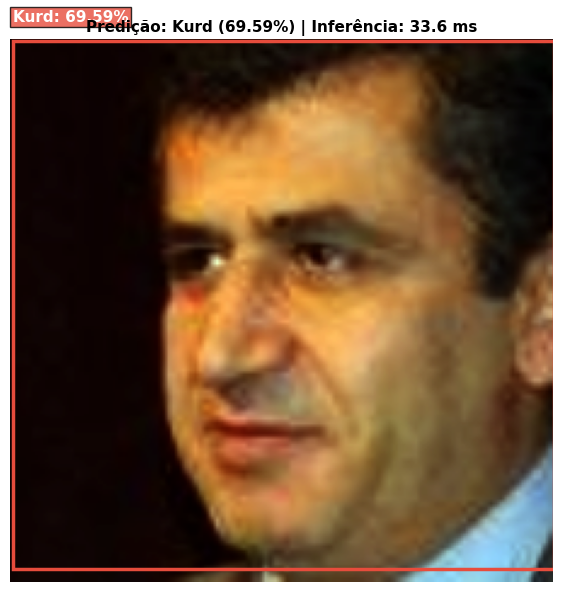

In [ ]:
@torch.no_grad()
def infer_single(model, img_path: str, device, score_threshold=0.3):
    """Executa inferência em uma imagem e exibe o resultado."""
    model.eval()

    # Pré-processamento
    img_bgr = preprocess(img_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_tensor = T.ToTensor()(Image.fromarray(img_rgb)).unsqueeze(0).to(device)

    # Inferência
    t0 = time.perf_counter()
    output = model(img_tensor)[0]
    elapsed_ms = (time.perf_counter() - t0) * 1000

    # Filtra detecções
    scores = output['scores'].cpu().numpy()
    labels = output['labels'].cpu().numpy()
    boxes  = output['boxes'].cpu().numpy()

    valid = scores > score_threshold

    # Visualização
    fig, ax = plt.subplots(1, figsize=(6, 6))
    ax.imshow(img_rgb)

    if valid.any():
        best = np.argmax(scores[valid])
        box   = boxes[valid][best]
        label = labels[valid][best]
        score = scores[valid][best]

        color = '#3498DB' if label == 1 else '#E74C3C'
        label_name = ID_TO_LABEL.get(label, 'Unknown')

        rect = patches.Rectangle(
            (box[0], box[1]), box[2]-box[0], box[3]-box[1],
            linewidth=2.5, edgecolor=color, facecolor='none'
        )
        ax.add_patch(rect)
        ax.text(box[0], box[1]-8, f'{label_name}: {score:.2%}',
                color='white', fontsize=11, fontweight='bold',
                bbox=dict(facecolor=color, alpha=0.8, pad=2))

        ax.set_title(f'Predição: {label_name} ({score:.2%}) | Inferência: {elapsed_ms:.1f} ms',
                     fontsize=11, fontweight='bold')
    else:
        ax.set_title(f'Nenhuma detecção acima do threshold ({score_threshold}) | {elapsed_ms:.1f} ms',
                     fontsize=11)

    ax.axis('off')
    plt.tight_layout()
    plt.show()


# Imagem de teste
TEST_IMAGE = '/content/dataset/test/kurd/00003_Adil_Zozan_C3_AE.jpg'

if Path(TEST_IMAGE).exists() and Path('faster_rcnn_best.pth').exists():
    model.load_state_dict(torch.load('faster_rcnn_best.pth', map_location=DEVICE))
    infer_single(model, TEST_IMAGE, DEVICE)
else:
    print(f'Altere TEST_IMAGE para o caminho de uma imagem real e treine o modelo primeiro.')

## 9. Comparativo de Backbones

Reproduz a Tabela 1 do paper e o trade-off acurácia × velocidade.

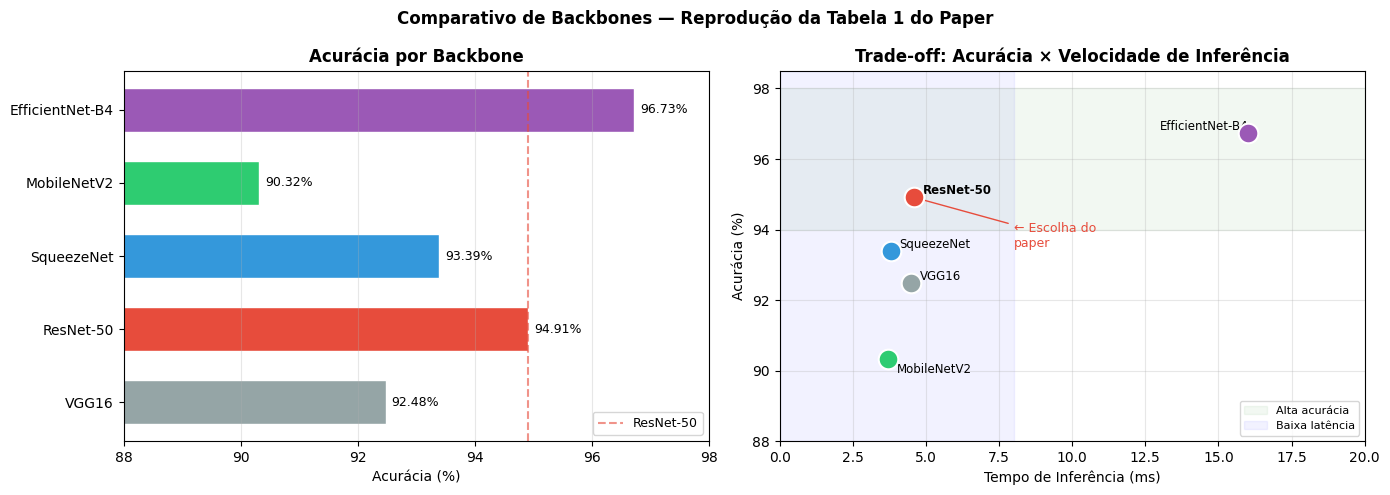

In [ ]:
backbones = ['VGG16', 'ResNet-50', 'SqueezeNet', 'MobileNetV2', 'EfficientNet-B4']
acc       = [92.48, 94.91, 93.39, 90.32, 96.73]
inf_time  = [4.5, 4.6, 3.8, 3.7, 16.0]
colors    = ['#95A5A6', '#E74C3C', '#3498DB', '#2ECC71', '#9B59B6']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Acurácia
bars = axes[0].barh(backbones, acc, color=colors, edgecolor='white', height=0.6)
axes[0].set_xlabel('Acurácia (%)')
axes[0].set_title('Acurácia por Backbone', fontweight='bold')
axes[0].set_xlim(88, 98)
axes[0].axvline(x=94.91, color='#E74C3C', linestyle='--', alpha=0.6, label='ResNet-50')
for bar, val in zip(bars, acc):
    axes[0].text(val + 0.1, bar.get_y() + bar.get_height()/2,
                 f'{val:.2f}%', va='center', fontsize=9)
axes[0].legend(fontsize=9)
axes[0].grid(axis='x', alpha=0.3)

# Gráfico 2: Trade-off Acurácia × Velocidade
for i, (b, a, t, c) in enumerate(zip(backbones, acc, inf_time, colors)):
    axes[1].scatter(t, a, s=200, color=c, zorder=5, edgecolors='white', linewidths=1.5)
    offset_x = 0.3 if b != 'EfficientNet-B4' else -3.0
    offset_y = 0.1 if b != 'MobileNetV2' else -0.4
    axes[1].annotate(b, (t + offset_x, a + offset_y), fontsize=8.5,
                     fontweight='bold' if b == 'ResNet-50' else 'normal')

# Região ideal: alta acurácia + baixa latência
axes[1].axhspan(94, 98, alpha=0.05, color='green', label='Alta acurácia')
axes[1].axvspan(0, 8, alpha=0.05, color='blue', label='Baixa latência')
axes[1].set_xlabel('Tempo de Inferência (ms)')
axes[1].set_ylabel('Acurácia (%)')
axes[1].set_title('Trade-off: Acurácia × Velocidade de Inferência', fontweight='bold')
axes[1].set_xlim(0, 20)
axes[1].set_ylim(88, 98.5)
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

# Destaca ResNet-50 como escolha ideal
axes[1].annotate(
    '← Escolha do\npaper', xy=(4.6, 94.91),
    xytext=(8, 93.5), fontsize=9, color='#E74C3C',
    arrowprops=dict(arrowstyle='->', color='#E74C3C')
)

plt.suptitle('Comparativo de Backbones — Reprodução da Tabela 1 do Paper',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## 10. Residual Block — Visualização do mecanismo central do ResNet-50

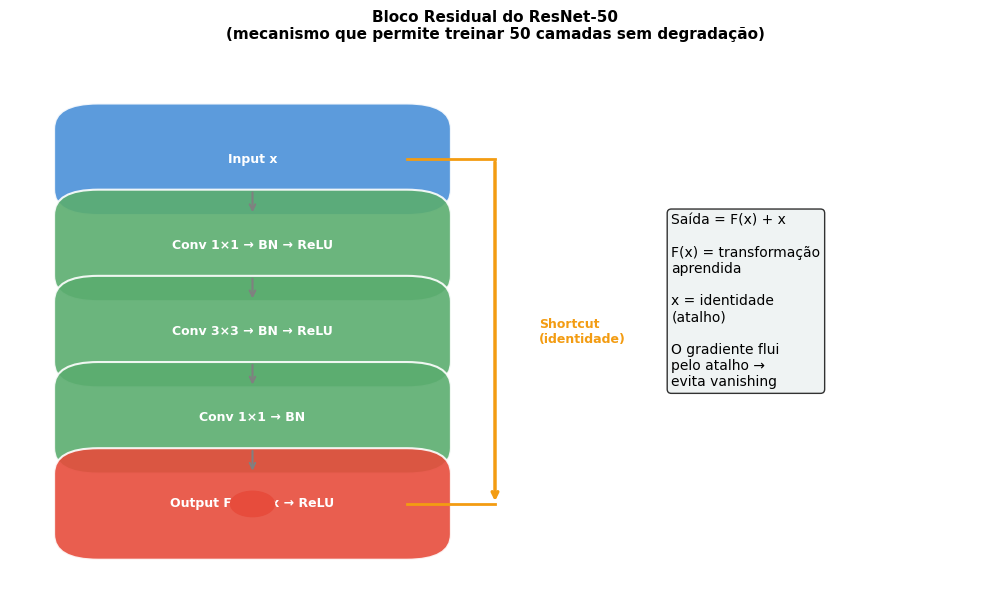

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.axis('off')

def draw_box(ax, x, y, w, h, label, color, fontsize=9):
    rect = patches.FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.05',
                                   facecolor=color, edgecolor='white', linewidth=1.5, alpha=0.9)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h/2, label, ha='center', va='center',
            fontsize=fontsize, color='white', fontweight='bold')

def arrow(ax, x1, y1, x2, y2, color='gray'):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color=color, lw=1.5))

# Blocos do residual
draw_box(ax, 0.1, 0.72, 0.35, 0.12, 'Input x', '#4A90D9')
draw_box(ax, 0.1, 0.55, 0.35, 0.12, 'Conv 1×1 → BN → ReLU', '#5BAD6F')
draw_box(ax, 0.1, 0.38, 0.35, 0.12, 'Conv 3×3 → BN → ReLU', '#5BAD6F')
draw_box(ax, 0.1, 0.21, 0.35, 0.12, 'Conv 1×1 → BN', '#5BAD6F')
draw_box(ax, 0.1, 0.04, 0.35, 0.12, 'Output F(x) + x → ReLU', '#E74C3C')

# Setas principais
arrow(ax, 0.275, 0.72,  0.275, 0.67)
arrow(ax, 0.275, 0.55,  0.275, 0.50)
arrow(ax, 0.275, 0.38,  0.275, 0.33)
arrow(ax, 0.275, 0.21,  0.275, 0.16)

# Shortcut connection
ax.annotate('', xy=(0.55, 0.10), xytext=(0.55, 0.78),
            arrowprops=dict(arrowstyle='->', color='#F39C12', lw=2.5,
                            connectionstyle='arc3,rad=0.0'))
ax.plot([0.45, 0.55], [0.78, 0.78], color='#F39C12', lw=2)
ax.plot([0.45, 0.55], [0.10, 0.10], color='#F39C12', lw=2)
ax.text(0.60, 0.44, 'Shortcut\n(identidade)', fontsize=9, color='#F39C12',
        va='center', fontweight='bold')

# Símbolo de soma
circle = plt.Circle((0.275, 0.10), 0.025, color='#E74C3C', zorder=5)
ax.add_patch(circle)
ax.text(0.275, 0.10, '+', ha='center', va='center', fontsize=14,
        color='white', fontweight='bold')

# Equação
ax.text(0.75, 0.5,
        'Saída = F(x) + x\n\nF(x) = transformação\naprendida\n\nx = identidade\n(atalho)\n\nO gradiente flui\npelo atalho →\nevita vanishing',
        ha='left', va='center', fontsize=10,
        bbox=dict(boxstyle='round', facecolor='#ECF0F1', alpha=0.8))

ax.set_xlim(0, 1.1)
ax.set_ylim(-0.05, 1.0)
ax.set_title('Bloco Residual do ResNet-50\n(mecanismo que permite treinar 50 camadas sem degradação)',
             fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

## 11. Resumo do pipeline

| Etapa | O que faz | Escolha do paper |
|---|---|---|
| Pré-processamento | Resize, isolamento facial, gamma, contraste | OpenCV |
| Augmentação | Brilho, rotação, flip, grayscale | torchvision |
| Backbone | Extrai features hierárquicas | **ResNet-50** (pré-treinado ImageNet) |
| FPN | Multi-escala para faces de diferentes tamanhos | torchvision |
| RPN | Propõe regiões candidatas (~300/imagem) | Faster R-CNN |
| ROI Pooling | Normaliza regiões para 7×7 | Faster R-CNN |
| Classificação | Softmax binário (Arab / Kurd) | FastRCNNPredictor |
| Métrica final | Acurácia 94.91%, F1 0.84, 4.6 ms | — |

**Limitação principal:** o modelo confunde árabes de pele clara com curdos e vice-versa, pois as features visuais se sobrepõem. A augmentação em grayscale mitiga, mas não resolve completamente o problema com apenas 260 imagens originais.